# Fake News Detection - Classical Models

In [1]:
import os
import json
import sys
import time
import joblib
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

# Folders for the dataset, figures and result tables
DATA_DIR = "../data/"
FIG_DIR = "../reports/figures/"
REPORT_DIR = "../reports/"
MODEL_DIR = "../models/"

# Folder with preprocess.py
APP_DIR = "../app/"

# For Google Colab: uncomment these lines to use Google Drive instead
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/fake-news/data/"
# FIG_DIR = "/content/drive/MyDrive/fake-news/reports/figures/"
# REPORT_DIR = "/content/drive/MyDrive/fake-news/reports/"
# MODEL_DIR = "/content/drive/MyDrive/fake-news/models/"
# APP_DIR = "/content/drive/MyDrive/fake-news/app/"

# Create the output folders if they do not exist
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# Let Python find preprocess.py so the app and notebooks share the same cleaning
sys.path.append(APP_DIR)
from preprocess import clean_text

In [2]:
# Load the train and test splits from the first notebook
train_df = pd.read_csv(DATA_DIR + "train.csv")
test_df = pd.read_csv(DATA_DIR + "test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (50822, 2)
Test shape: (12706, 2)


In [3]:
# Two training articles before and after cleaning (first 300 characters)
for text in train_df["content"].head(2):
    print("Before:", text[:300])
    print("After: ", clean_text(text)[:300])
    print()

Before: Zimbabwe's Mugabe is gone, but political kow-towing still abounds Robert Mugabe s 37-year rule may be over, but a culture of political fawning by the Zimbabwean state media and fear of those in authority still flourishes. The Herald newspaper and the Zimbabwe Broadcasting Corporation - state and rul


After:  zimbabwe mugabe gone political kow towing still abounds robert mugabe year rule may culture political fawning zimbabwean state medium fear authority still flourish herald newspaper zimbabwe broadcasting corporation state ruling zanu party mouthpiece routinely heaped lavish praise year old mugabe wif

Before: Trump Just Praised Fox News’ Ratings And Attacked CNN Again Then Got CRUSHED By Twitter (TWEETS) If you haven t yet heard that Fox News came out on top in ratings during Donald Trump s inauguration, all you need to do is check President Asterisk s Twitter timeline. After a rousing first few days of 
After:  trump praised fox news rating attacked cnn got crushed twitter tweet haven yet heard fox news came top rating donald trump inauguration need check president asterisk twitter timeline rousing first day working toward dismantling obamacare endangering health woman girl worldwide signing environment aw



In [4]:
# Clean every article (this takes a few minutes)
# fillna("") turns any empty article (read back as NaN) into empty text
train_df["clean"] = train_df["content"].fillna("").apply(clean_text)
test_df["clean"] = test_df["content"].fillna("").apply(clean_text)

In [5]:
# Save the cleaned splits so we don't have to clean again
train_df.to_csv(DATA_DIR + "train_clean.csv", index=False)
test_df.to_csv(DATA_DIR + "test_clean.csv", index=False)
print("Saved train_clean.csv and test_clean.csv")

Saved train_clean.csv and test_clean.csv


## Preprocessing steps

- **Tokenization:** the text is lowercased, URLs, HTML tags and non-letters are removed, and the rest is split into words on spaces.
- **Stopword removal:** common words like "the" and "is" are removed, but negations ("not", "no", "nor", and "don", "isn", "wasn" etc. because apostrophes were stripped) are kept, since they can flip the meaning.
- **Lemmatization vs stemming:** lemmatization turns words into real dictionary forms ("bills" -> "bill"), while stemming just chops endings and can give non-words ("studies" -> "studi").
- **Same function in the app:** `clean_text` lives in `app/preprocess.py`, so the Streamlit app cleans new text exactly like the training data; otherwise the model would see differently formatted input.

## TF-IDF Features

In [6]:
# Load the cleaned splits (so this section can run without cleaning again)
train_df = pd.read_csv(DATA_DIR + "train_clean.csv")
test_df = pd.read_csv(DATA_DIR + "test_clean.csv")

# Some articles are empty after cleaning (e.g. non-English text), so fill them with ""
X_train = train_df["clean"].fillna("")
X_test = test_df["clean"].fillna("")
y_train = train_df["is_fake"]
y_test = test_df["is_fake"]

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 50822
Test rows: 12706


In [7]:
# TF-IDF settings, reused by every model in this notebook
TFIDF_PARAMS = dict(
    ngram_range=(1, 2),   # use single words and pairs of words
    max_features=50000,   # keep the 50,000 most frequent terms
    min_df=3,             # ignore terms found in fewer than 3 articles
    max_df=0.9,           # ignore terms found in more than 90% of articles
    sublinear_tf=True,    # use 1 + log(count) so repeated words don't dominate
)

In [8]:
vec = TfidfVectorizer(**TFIDF_PARAMS)

# Learn the vocabulary from the training data only.
# Fitting on test data would leak information about the test set into the model.
X_train_tfidf = vec.fit_transform(X_train)
X_test_tfidf = vec.transform(X_test)

print("Train matrix shape:", X_train_tfidf.shape)
print("Test matrix shape:", X_test_tfidf.shape)

Train matrix shape: (50822, 50000)
Test matrix shape: (12706, 50000)


In [9]:
feature_names = pd.Series(vec.get_feature_names_out())
print("Vocabulary size:", len(feature_names))

# 10 random single words and 10 random word pairs
is_bigram = feature_names.str.contains(" ")
print("\nUnigrams:", list(feature_names[~is_bigram].sample(10, random_state=42)))
print("Bigrams:", list(feature_names[is_bigram].sample(10, random_state=42)))

Vocabulary size: 50000

Unigrams: ['announce', 'indigenous', 'est', 'bonanza', 'mogadishu', 'exemplified', 'tyranny', 'diving', 'actually', 'bumpy']
Bigrams: ['labor secretary', 'day police', 'said went', 'estimated cost', 'scott walker', 'corruption case', 'telling american', 'act law', 'session said', 'sunday want']


## How TF-IDF works

- **TF (term frequency):** how often a word appears in one article; here we use 1 + log(count) so a word used 50 times doesn't count 50 times more.
- **IDF (inverse document frequency):** how rare a word is across all articles; words found in almost every article get a low weight.
- **TF x IDF:** a word gets a high score when it is common in this article but rare overall, so the distinctive words of each article stand out.
- **Sparse matrix:** each article uses only a few hundred of the 50,000 terms, so most values are 0 and only the non-zero values are stored.

## Model Training

In [10]:
# The four classical models we compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
}

/Users/vaishnavi/Desktop/Fake News Detection/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


In [11]:
train_times = {}  # training time in seconds for each model
trained = {}      # fitted models

for name, model in models.items():
    start = time.time()
    model.fit(X_train_tfidf, y_train)
    train_times[name] = round(time.time() - start, 2)
    trained[name] = model
    print(f"{name}: {train_times[name]} seconds")

Logistic Regression: 0.72 seconds
Naive Bayes: 0.02 seconds


Passive Aggressive: 0.57 seconds


Linear SVM: 1.62 seconds


In [12]:
# Quick check: accuracy on the test set
for name, model in trained.items():
    y_pred = model.predict(X_test_tfidf)
    print(f"{name}: {accuracy_score(y_test, y_pred):.4f}")

Logistic Regression: 0.9320
Naive Bayes: 0.8568
Passive Aggressive: 0.9355
Linear SVM: 0.9411


## How each model decides

- **Logistic Regression:** gives each word a weight, adds them up, and turns the total into a fake probability with the sigmoid function.
- **Naive Bayes:** uses Bayes' theorem to pick the more likely class, assuming each word appears independently of the others.
- **Passive Aggressive:** updates its weights only when it makes a mistake, so it can keep learning from a stream of new articles.
- **Linear SVM:** finds the line (hyperplane) that separates real and fake articles with the widest possible margin.

## Evaluation

In [13]:
rows = []
predictions = {}  # test predictions of each model, reused below

for name, model in trained.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    # ROC-AUC needs scores: probabilities if the model has them, otherwise decision scores
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_test_tfidf)

    # Precision, recall and F1 treat fake (1) as the positive class
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Train time (s)": train_times[name],
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False).round(4)
results.to_csv(REPORT_DIR + "results_classical.csv")
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
Model,,,,,,
Linear SVM,0.9411,0.9348,0.9349,0.9349,0.9854,1.62
Passive Aggressive,0.9355,0.9308,0.9262,0.9285,0.9832,0.57
Logistic Regression,0.9320,0.9232,0.9268,0.9250,0.9805,0.72
Naive Bayes,0.8568,0.8181,0.8789,0.8474,0.9303,0.02


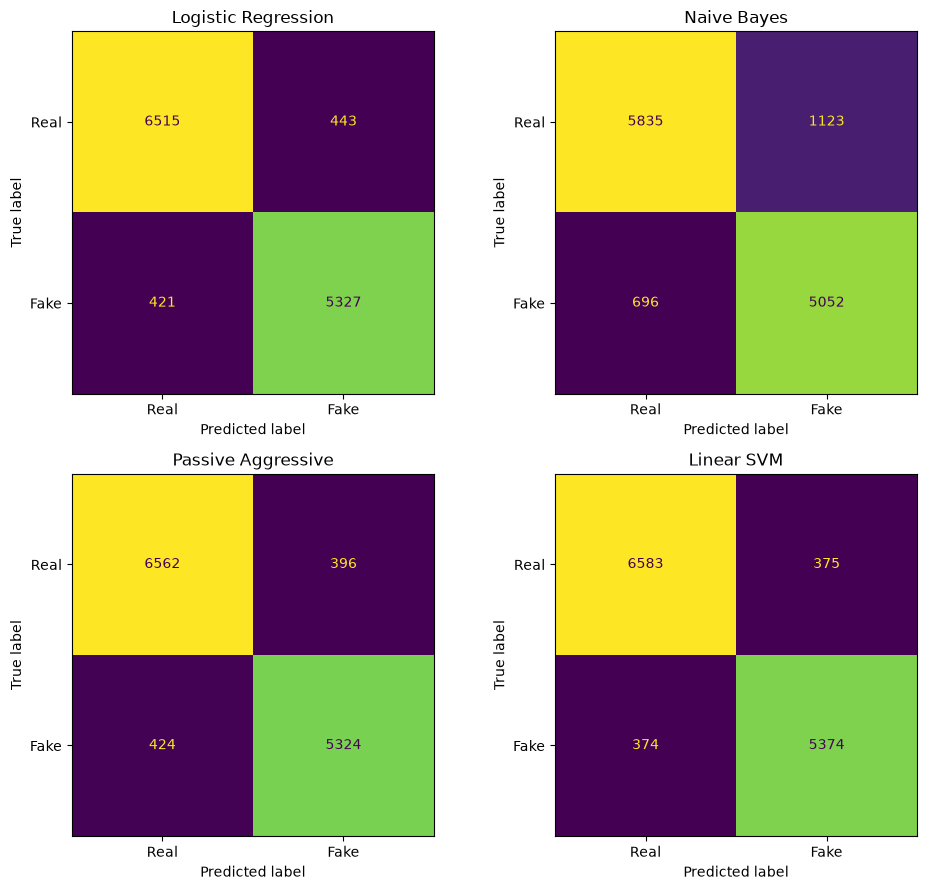

In [14]:
# Confusion matrix for each model
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Real", "Fake"], colorbar=False, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(FIG_DIR + "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

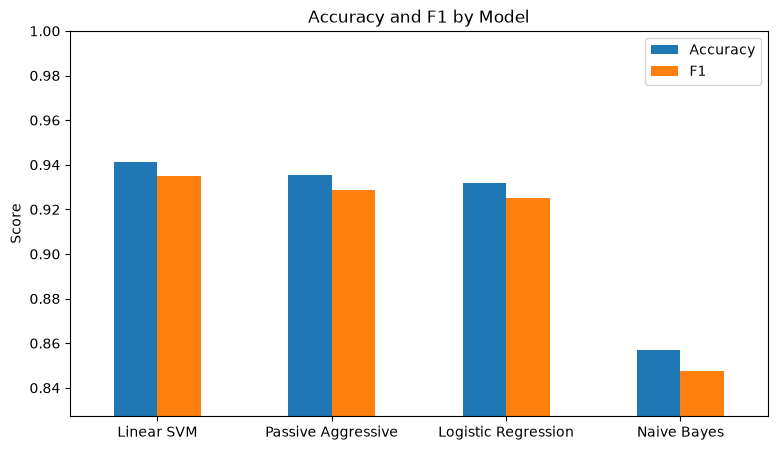

In [15]:
# Accuracy and F1 side by side for each model
scores = results[["Accuracy", "F1"]]
ax = scores.plot(kind="bar", figsize=(9, 5), rot=0)

# Start the y-axis just below the lowest score so differences are visible
ax.set_ylim(scores.min().min() - 0.02, 1.0)
ax.set_title("Accuracy and F1 by Model")
ax.set_xlabel("")
ax.set_ylabel("Score")

plt.savefig(FIG_DIR + "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Best model = highest F1 (first row of the sorted results)
best_name = results.index[0]
print("Best model by F1:", best_name)

# Table of true vs predicted labels for every test article
labels = {0: "Real", 1: "Fake"}
errors = pd.DataFrame({
    "content": test_df["content"].str[:300],
    "true": y_test.map(labels),
    "predicted": pd.Series(predictions[best_name], index=test_df.index).map(labels),
})

# Keep only the articles the model got wrong
errors = errors[errors["true"] != errors["predicted"]]

print("False positives (real flagged as fake):", (errors["true"] == "Real").sum())
print("False negatives (fake missed as real):", (errors["true"] == "Fake").sum())

# Show the full 300 characters instead of cutting them short
pd.set_option("display.max_colwidth", 300)
errors.head(5)

Best model by F1: Linear SVM
False positives (real flagged as fake): 375
False negatives (fake missed as real): 374


,content,true,predicted
10,"All dogs on dog Tinder All dogs on dog Tinder 14-11-16 DOGS are using social media for no-strings hookups with other dogs, it has emerged. Experts believe that all dogs are using dog phone apps to meet fellows dogs for secret liaisons, often under their owners’ noses. Stephen Malley, a golden re...",Fake,Real
15,Clinton Camp in Damage-Control Mode Over 'Top Secret' Emails The latest revelations on Hillary's emails again point to one thing → She is disqualified from being president.,Real,Fake
80,"The White House’s Overflowing In-box The White House’s Overflowing In-box Written by Ralph R. Reiland Email No matter whether it’s Trump or Clinton who wins the election, the victor will be confronted with an inbox brimming over with acute social and economic difficulties. Nevertheless, regardin...",Fake,Real
96,"Watch: Pentagon Released Explosion Footage for ’Mother of All Bombs’ Dropped on Afghanistan New video of massive bomb hitting ISIS CNN aired footage Friday of the or “Massive Ordnance Air Blast,” dropped Thursday on the Islamic State in Afghanistan. The bomb, also known as the “Mother of All Bom...",Real,Fake
110,"Trump staff writer takes responsibility for Melania speech controversy A staff writer of the Trump Organization, the company owned by Republican presidential candidate Donald Trump, has claimed responsibility for inserting passages in a speech given at the Republican National Convention by Trump...",Real,Fake


## Why these were wrong

- **Fake articles written like real news:** the dog Tinder story is satire, but it copies the news style ("it has emerged", "Experts believe", a quote from a named person). The White House in-box article is a calm opinion piece about economic problems with a "Written by" line. Neither uses clickbait words, so I think the model saw them as real.
- **Real articles with clickbait words:** the Pentagon bomb article starts with "Watch:" and talks about a "New video" of a "massive bomb". "video", "watch" and "massive" are all top fake words, so they outweighed the real signs like "Friday" and "Thursday".
- **Short real articles about scandals:** the Clinton emails article is only two sentences, uses "Hillary" (a strong fake word) and sounds like an opinion ("She is disqualified from being president"). The Melania speech article is about a "controversy" around Trump's campaign, a topic that fake sites wrote about a lot. With so little text and these topics, the model had little else to go on, which shows it judges words and style, not whether the story is true.

## Metrics explained

- **Precision:** of the articles the model flagged as fake, how many really were fake.
- **Recall:** of all the fake articles, how many the model caught.
- **F1 (main metric):** the balance of precision and recall in one number, so a model can't look good by being strong at only one of them.
- **Which error is worse:** a false negative (fake news missed) lets misinformation spread, which is usually worse; a false positive (real news flagged) hurts trust in the tool, so both matter.

## Hyperparameter Tuning

In [17]:
# TF-IDF and the classifier in one pipeline, so TF-IDF is refitted inside
# each cross-validation fold and never sees that fold's validation data (no leakage)
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("clf", LinearSVC(random_state=42)),
])

In [18]:
# Try different C values for Linear SVM.
# Logistic Regression was dropped from tuning because it scored lower than
# Linear SVM in the Evaluation step and was slow to converge.
param_grid = [
    {"clf": [LinearSVC(random_state=42)], "clf__C": [0.1, 0.5, 1, 2]},
]

# n_jobs=2 runs 2 fits at a time, which uses less memory than all CPU cores
grid = GridSearchCV(pipe, param_grid, cv=3, scoring="f1", n_jobs=2, verbose=1)

# Fit on the cleaned text, not the TF-IDF matrix (the pipeline builds TF-IDF itself).
# This takes about 5-10 minutes.
grid.fit(X_train, y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'clf': [LinearSVC(random_state=42)], 'clf__C': [0.1, 0.5, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how t

In [19]:
print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))

# Mean cross-validation F1 for every combination
cv_results = pd.DataFrame(grid.cv_results_)
cv_table = pd.DataFrame({
    "Model": cv_results["param_clf"].apply(lambda clf: type(clf).__name__),
    "C": cv_results["param_clf__C"],
    "Mean CV F1": cv_results["mean_test_score"].round(4),
}).sort_values("Mean CV F1", ascending=False)
cv_table

Best parameters: {'clf': LinearSVC(random_state=42), 'clf__C': 0.5}
Best CV F1: 0.9314


,Model,C,Mean CV F1
1,LinearSVC,0.5,0.9314
2,LinearSVC,1.0,0.9312
3,LinearSVC,2.0,0.9288
0,LinearSVC,0.1,0.9222


In [20]:
best_model = grid.best_estimator_

# Same names as in the results table
model_names = {"LinearSVC": "Linear SVM", "LogisticRegression": "Logistic Regression"}
tuned_name = model_names[type(best_model.named_steps["clf"]).__name__]

# Evaluate on the test set once
y_pred = best_model.predict(X_test)
if hasattr(best_model, "predict_proba"):
    tuned_scores = best_model.predict_proba(X_test)[:, 1]
else:
    tuned_scores = best_model.decision_function(X_test)

results.loc[f"Tuned {tuned_name}"] = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
    "Train time (s)": grid.refit_time_,  # time to refit the best model on all training data
})

results = results.round(4)
results.to_csv(REPORT_DIR + "results_classical.csv")
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
Model,,,,,,
Linear SVM,0.9411,0.9348,0.9349,0.9349,0.9854,1.6200
Passive Aggressive,0.9355,0.9308,0.9262,0.9285,0.9832,0.5700
Logistic Regression,0.9320,0.9232,0.9268,0.9250,0.9805,0.7200
Naive Bayes,0.8568,0.8181,0.8789,0.8474,0.9303,0.0200
Tuned Linear SVM,0.9416,0.9350,0.9360,0.9355,0.9856,32.5293


In [21]:
# Save the best settings so later steps can reuse them
best_params = {"model": tuned_name, "C": grid.best_params_["clf__C"]}

with open(REPORT_DIR + "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

print("Saved best_params.json:", best_params)

Saved best_params.json: {'model': 'Linear SVM', 'C': 0.5}


## Tuning explained

- **C:** controls how strictly the model fits the training data; a small C keeps the model simple (more regularization), a large C fits the training data more closely but can overfit.
- **3-fold cross-validation:** the training set is split into 3 parts; each combination is trained on 2 parts and scored on the third, 3 times, and the average F1 is used to compare them.
- **Test set used once:** all choices are made with cross-validation on the training data, so the test score stays an honest estimate of performance on new articles.
- **Why only Linear SVM:** it had the best F1 in the Evaluation step, so tuning only it keeps the search fast (12 fits instead of 21) on a laptop, and Logistic Regression scored lower.

## Explainability

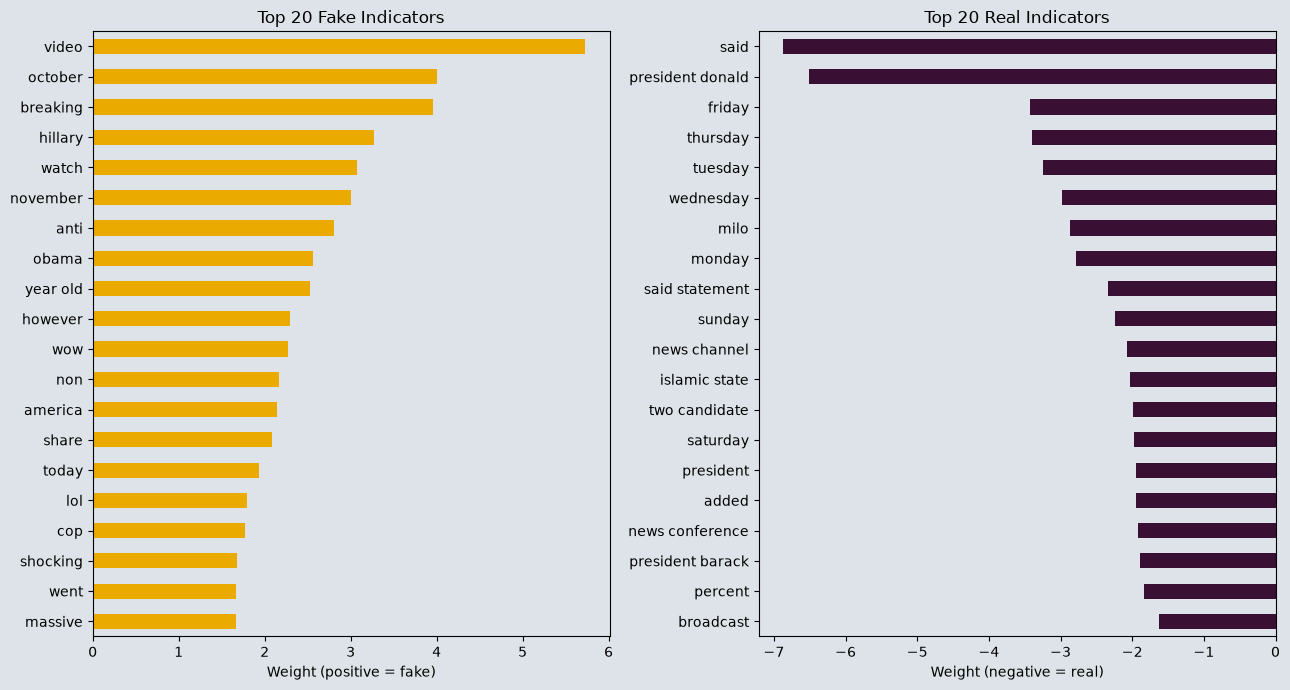

In [22]:
# Word weights from the tuned TF-IDF + Linear SVM
tuned_tfidf = grid.best_estimator_.named_steps["tfidf"]
tuned_svm = grid.best_estimator_.named_steps["clf"]
weights = pd.Series(tuned_svm.coef_[0], index=tuned_tfidf.get_feature_names_out())

# Highest weights push towards fake (1), lowest push towards real (0)
top_fake = weights.sort_values().tail(20)
top_real = weights.sort_values().head(20).sort_values(ascending=False)  # most negative at the top

# App theme colours
FAKE_COLOR = "#EAAA00"
REAL_COLOR = "#3A0F34"
BACKGROUND = "#DDE3E8"

fig, axes = plt.subplots(1, 2, figsize=(13, 7), facecolor=BACKGROUND)

top_fake.plot(kind="barh", ax=axes[0], color=FAKE_COLOR)
axes[0].set_title("Top 20 Fake Indicators")
axes[0].set_xlabel("Weight (positive = fake)")

top_real.plot(kind="barh", ax=axes[1], color=REAL_COLOR)
axes[1].set_title("Top 20 Real Indicators")
axes[1].set_xlabel("Weight (negative = real)")

for ax in axes:
    ax.set_facecolor(BACKGROUND)

plt.tight_layout()
plt.savefig(FIG_DIR + "top_words.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Best C from the tuning step
with open(REPORT_DIR + "best_params.json") as f:
    best_C = json.load(f)["C"]

# LinearSVC has no probabilities, so calibration adds them
# for LIME and for the confidence % in the app
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("clf", CalibratedClassifierCV(LinearSVC(C=best_C, random_state=42), cv=3)),
])
final_model.fit(X_train, y_train)

# Should be close to the tuned model's test F1
final_pred = final_model.predict(X_test)
print("Final model test F1:", round(f1_score(y_test, final_pred), 4))
print("Tuned model test F1:", results.loc[f"Tuned {tuned_name}", "F1"])

Final model test F1: 0.9348
Tuned model test F1: 0.9355


In [24]:
def predict_raw(texts):
    """Clean raw texts like the training data, then return [P(real), P(fake)] for each."""
    cleaned = [clean_text(text) for text in texts]
    return final_model.predict_proba(cleaned)


explainer = LimeTextExplainer(class_names=["Real", "Fake"], random_state=42)

# First correctly predicted fake and real articles in the test set
correct = final_pred == y_test
fake_idx = test_df.index[correct & (y_test == 1)][0]
real_idx = test_df.index[correct & (y_test == 0)][0]

for label, idx in [("fake", fake_idx), ("real", real_idx)]:
    print(f"Correctly predicted {label} article (test row {idx}):")
    exp = explainer.explain_instance(
        test_df.loc[idx, "content"], predict_raw, num_features=10, num_samples=1000
    )
    # Show the explanation (same as exp.show_in_notebook, which fails with newer IPython)
    display(HTML(exp.as_html(text=True)))
    exp.save_to_file(FIG_DIR + f"lime_{label}.html")

Correctly predicted fake article (test row 0):


Correctly predicted real article (test row 2):


## Leakage fix

- An earlier run of this notebook showed the model relying on website boilerplate, not the writing: "via" was the strongest fake word, followed by "twitter com", "featured image", "entire story", "loading", "nyp" and "snip", while "follow twitter", "twitter email", "http" and "factbox" pushed towards real.
- These phrases (image and source credits, embedded tweets, page buttons, Reuters credits and author sign-offs) were then removed in the cleaning step of `01_eda.ipynb`, so all results and top words in this notebook come from the cleaned data.

## What the model learned

- **What the model relies on:** mostly *writing style*, not facts. Real news is pushed by reporting words like "said", "said statement", "added", "news conference" and "percent" and by weekdays ("friday", "thursday", "tuesday"), which is how news agencies write. Fake news is pushed by clickbait and social-media words like "video", "breaking", "watch", "wow", "lol", "shocking", "share" and "massive".
- **Effect of the leakage fix:** none of the top words come from website boilerplate any more ("via", "twitter com", "featured image", "loading", "snip" and "factbox" are gone). The final model's test F1 dropped from 0.9517 to 0.9348, which is a more honest score because the model can no longer recognise the website layout.
- **Any suspicious words (possible bias):** some words still point to *when* and *who* rather than the writing: "october" and "november" point to the 2016 election period when many fake articles were collected, and "milo" points to one person who was covered a lot by one real-news site. Fake articles often name "hillary" and "obama" directly while real ones write "president donald" or "president barack", so the model may unfairly flag any article that talks about Hillary Clinton or Obama informally.

## Explainability explained

- **Global explanation (top words):** the Linear SVM gives every word one weight for all articles; the largest positive weights point to fake and the largest negative weights point to real.
- **Local explanation (LIME):** for one article, LIME removes random words many times, watches how the prediction changes, and shows which words pushed this article towards real or fake.
- **Why calibration was needed:** Linear SVM only gives a score, not a probability; `CalibratedClassifierCV` turns that score into a real probability, which LIME needs and which the app shows as a confidence %.

## Save Final Model

In [25]:
# Older scikit-learn versions keep a large stop_words_ list that is not needed
# for predictions; remove it to make the file smaller (newer versions don't have it)
tfidf = final_model.named_steps["tfidf"]
if hasattr(tfidf, "stop_words_"):
    tfidf.stop_words_ = None

# Save the model (compress=3 makes the file smaller)
os.makedirs(MODEL_DIR, exist_ok=True)
model_path = MODEL_DIR + "fake_news_model.joblib"
joblib.dump(final_model, model_path, compress=3)

# Test-set scores of the saved model, shown in the app
final_pred = final_model.predict(X_test)
model_info = {
    "model_name": "Linear SVM + TF-IDF",
    "best_C": best_C,
    "accuracy": round(accuracy_score(y_test, final_pred), 4),
    "precision": round(precision_score(y_test, final_pred), 4),
    "recall": round(recall_score(y_test, final_pred), 4),
    "f1": round(f1_score(y_test, final_pred), 4),
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "sklearn_version": sklearn.__version__,
}
with open(MODEL_DIR + "model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

print("Model file size:", round(os.path.getsize(model_path) / 1024**2, 1), "MB")
print("scikit-learn version:", sklearn.__version__)

Model file size: 1.7 MB
scikit-learn version: 1.9.1
